# Statistical Learning — Part 1
This notebook illustrates the following statistical models

- **Logistic Regression** for probabilistic binary classification
- **Softmax Regression** for mutually exclusive multiclass outcomes



## 0. Environment setup

The notebook uses NumPy, pandas, Matplotlib, Seaborn, and scikit-learn. All random processes use a fixed seed so the results are reproducible.

In [53]:
# Import libraries for computing, visualization, and modeling
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import ListedColormap
from sklearn.calibration import calibration_curve
from sklearn.datasets import (
    load_breast_cancer,
    make_blobs,
    make_circles,
    make_classification,
    make_moons,
)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    log_loss,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# Suppress warning outputs that do not affect the demonstration content
warnings.filterwarnings("ignore")

# Set static seed for reproducibility across runs
SEED = 42
np.random.seed(SEED)

# Configure a consistent plotting style for the entire notebook
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "figure.figsize": (9, 5),
    "figure.dpi": 110,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
})

COLORS = {
    "blue": "#0A2A6B",
    "orange": "#D97000",
    "green": "#4E8B3A",
    "red": "#C1121F",
    "purple": "#7B2CBF",
    "gold": "#D4A300",
    "gray": "#6C757D",
}

print(f"Environment ready. Reproducible seed: {SEED}")

Environment ready. Reproducible seed: 42


# 1. Logistic Regression

Logistic Regression combines a linear score with the sigmoid function:

$$z = w^T x + b, \qquad P(y=1\mid x)=\sigma(z)=\frac{1}{1+e^{-z}}$$

The model learns parameters by minimizing binary cross-entropy:

$$\mathcal{L}=-\frac{1}{N}\sum_{i=1}^{N}\left[y_i\log p_i+(1-y_i)\log(1-p_i)\right]$$

The default threshold of 0.5 creates a linear decision boundary, but applications may choose a different threshold to balance precision and recall.

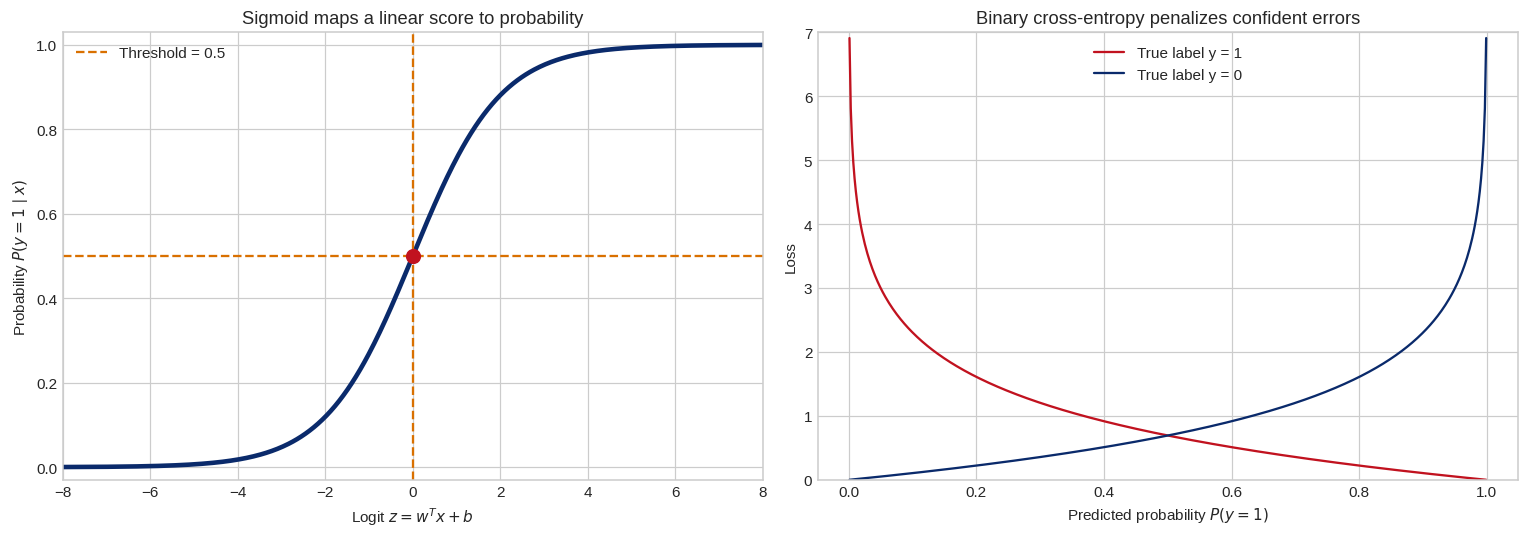

In [54]:
# Define sigmoid and binary cross-entropy to inspect formulas directly
def sigmoid(z: np.ndarray | float) -> np.ndarray | float:
    '''Return sigmoid probabilities for one value or a NumPy array.'''
    return 1.0 / (1.0 + np.exp(-z))


def binary_cross_entropy(y_true: int, probability: np.ndarray) -> np.ndarray:
    '''Return binary cross-entropy for a fixed binary target and probabilities.'''
    # Clip probabilities to avoid log(0) during numerical evaluation
    probability = np.clip(probability, 1e-10, 1 - 1e-10)
    return -(y_true * np.log(probability) + (1 - y_true) * np.log(1 - probability))


# Generate logit domain and probability domain for the two plots
# Create an array of 500 equally spaced values from -8 to 8
z_values = np.linspace(-8, 8, 500)
probabilities = sigmoid(z_values)
p_values = np.linspace(0.001, 0.999, 500)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left plot: how sigmoid maps logit to probability
axes[0].plot(z_values, probabilities, color=COLORS["blue"], linewidth=3)
axes[0].axhline(0.5, color=COLORS["orange"], linestyle="--", label="Threshold = 0.5")
axes[0].axvline(0, color=COLORS["orange"], linestyle="--")
axes[0].scatter([0], [0.5], color=COLORS["red"], s=80, zorder=5)
axes[0].set(
    title="Sigmoid maps a linear score to probability",
    xlabel=r"Logit $z=w^Tx+b$",
    ylabel=r"Probability $P(y=1\mid x)$",
    xlim=(-8, 8),
    ylim=(-0.03, 1.03),
)
axes[0].legend()

# Right plot: showing how incorrect but overly confident predictions are penalized
axes[1].plot(p_values, binary_cross_entropy(1, p_values), color=COLORS["red"], label="True label y = 1")
axes[1].plot(p_values, binary_cross_entropy(0, p_values), color=COLORS["blue"], label="True label y = 0")
axes[1].set(
    title="Binary cross-entropy penalizes confident errors",
    xlabel=r"Predicted probability $P(y=1)$",
    ylabel="Loss",
    ylim=(0, 7),
)
axes[1].legend()

plt.tight_layout()
plt.show()

## 1.1 Training and the decision boundary

The next example uses two standardized features. The colored background shows the estimated probability, and the black contour marks the 0.5 decision boundary.

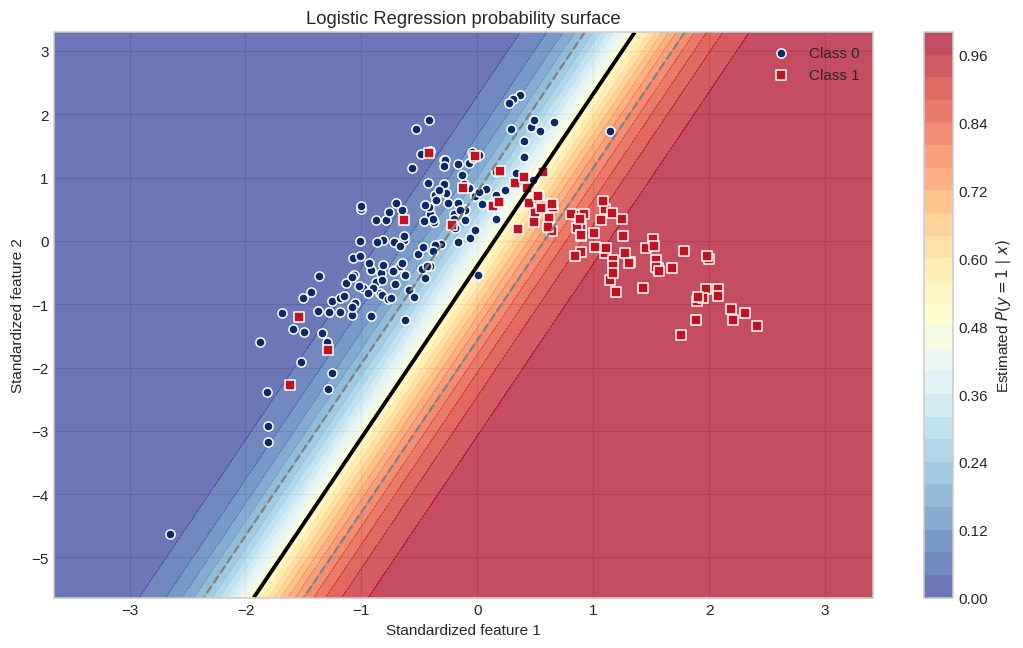

Learned coefficients: [ 3.216 -1.184]
Intercept: -0.468
Test accuracy: 0.958


In [55]:
# Generate 2D binary dataset for visualizing decision boundaries
X_binary, y_binary = make_classification(
    n_samples=320,          # Generate a total of 320 samples
    n_features=2,           # 2 features per sample (2D, easy to visualize)
    n_redundant=0,          # No redundant features constructed from others
    n_informative=2,        # Both features carry classification information
    n_clusters_per_class=1, # Exactly 1 cluster of data per class
    class_sep=1.25,         # Degree of separation between classes (larger means easier)
    flip_y=0.05,            # Flip 5% of labels randomly to introduce noise
    weights=[0.65, 0.35],   # 65% class 0 and 35% class 1 (imbalanced data)
    random_state=SEED,      # Fixed seed for reproducible output
)

# Stratified train-test split to keep class proportions stable
X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(
    X_binary,                # Input feature matrix
    y_binary,                # Target label vector
    test_size=0.30,          # 30% data for test set, 70% for train set
    stratify=y_binary,       # Preserve class distributions in train and test splits
    random_state=SEED,       # Fixed seed for consistent splitting
)

# Fit standard scaler only on the training set to prevent data leakage
scaler_binary = StandardScaler()
X_train_bs = scaler_binary.fit_transform(X_train_b)
X_test_bs = scaler_binary.transform(X_test_b)

# Train Logistic Regression with L2 regularization
logistic_model = LogisticRegression(C=1.0, max_iter=1000, random_state=SEED)
logistic_model.fit(X_train_bs, y_train_b)

# Generate 2D grid and evaluate probabilities at each grid point
# Retrieve min and max values for first feature (column 0)
# and extend by 1 unit to avoid clipping at borders
x_min, x_max = X_train_bs[:, 0].min() - 1, X_train_bs[:, 0].max() + 1

# Retrieve min and max values for second feature (column 1)
# and extend by 1 unit
y_min, y_max = X_train_bs[:, 1].min() - 1, X_train_bs[:, 1].max() + 1

# Generate a 2D coordinate grid of 350 x 350 points
xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 350),
    np.linspace(y_min, y_max, 350),
)

# Flatten 2D grid into a list of (x, y) coordinates for model prediction
grid = np.c_[xx.ravel(), yy.ravel()]

# Predict probabilities of class 1 for each grid coordinate
# [:, 1] extracts probabilities for class 1
# reshape(xx.shape) restores dimensions back to 350 x 350 grid
grid_probabilities = logistic_model.predict_proba(grid)[:, 1].reshape(xx.shape)

fig, ax = plt.subplots(figsize=(10, 6))
surface = ax.contourf(xx, yy, grid_probabilities, levels=25, cmap="RdYlBu_r", alpha=0.72)
ax.contour(xx, yy, grid_probabilities, levels=[0.5], colors="black", linewidths=2.5)
ax.contour(xx, yy, grid_probabilities, levels=[0.2, 0.8], colors="gray", linestyles="--")
ax.scatter(X_train_bs[y_train_b == 0, 0], X_train_bs[y_train_b == 0, 1], color=COLORS["blue"], edgecolor="white", label="Class 0")
ax.scatter(X_train_bs[y_train_b == 1, 0], X_train_bs[y_train_b == 1, 1], color=COLORS["red"], marker="s", edgecolor="white", label="Class 1")
plt.colorbar(surface, ax=ax, label=r"Estimated $P(y=1\mid x)$")
ax.set(title="Logistic Regression probability surface", xlabel="Standardized feature 1", ylabel="Standardized feature 2")
ax.legend()
plt.tight_layout()
plt.show()

# Print weights associated with each input feature
print("Learned coefficients:", logistic_model.coef_[0].round(3))
# Print intercept (bias) learned by the model
print("Intercept:", logistic_model.intercept_[0].round(3))
# Evaluate model accuracy on the test set
print("Test accuracy:", round(logistic_model.score(X_test_bs, y_test_b), 3))

## 1.2 Threshold tuning and evaluation

A lower threshold usually detects more positive cases, but it may also create more false alarms. The confusion matrices below make this tradeoff visible. ROC and precision-recall curves evaluate performance across many thresholds.

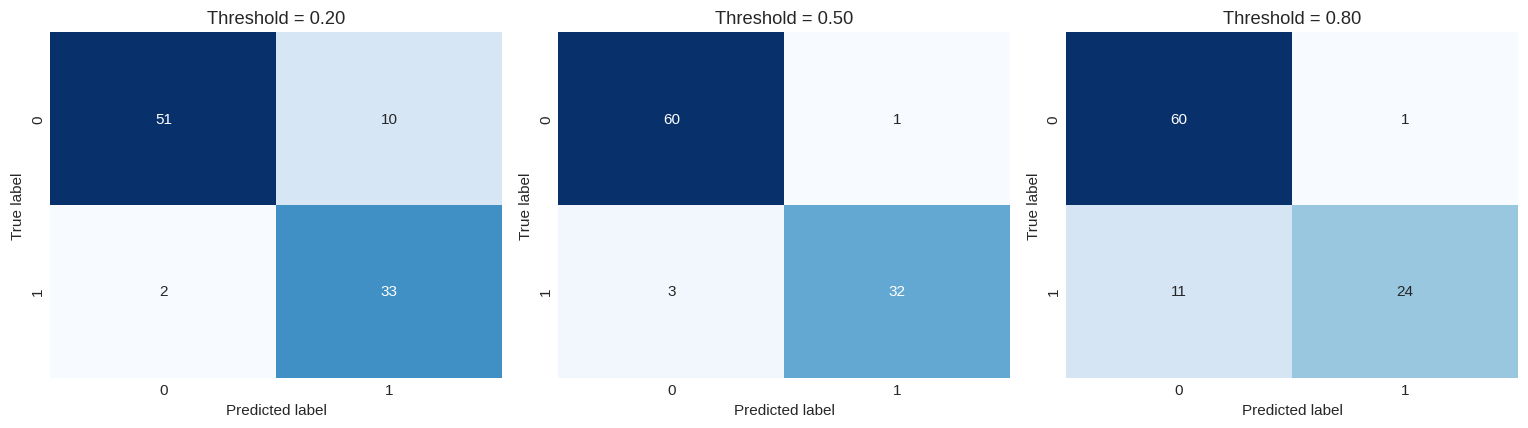

,Threshold,Precision,Recall,F1
0,0.2,0.767,0.943,0.846
1,0.5,0.970,0.914,0.941
2,0.8,0.960,0.686,0.800


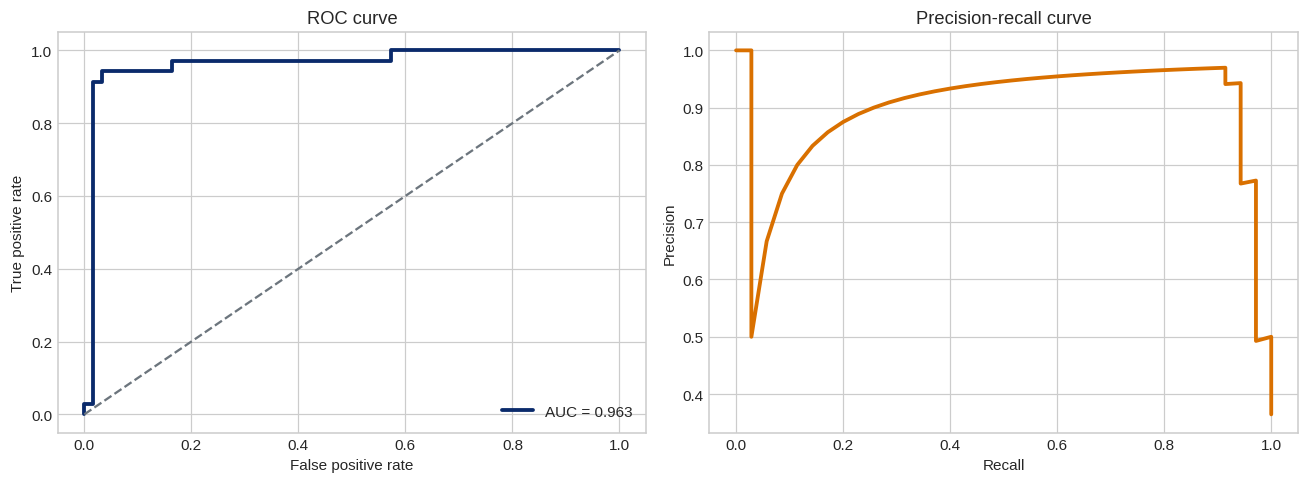

In [56]:
# Calculate positive-class probabilities on the test set
y_probability_b = logistic_model.predict_proba(X_test_bs)[:, 1]

# Evaluate and compare decision thresholds with metrics and confusion matrices
thresholds = [0.20, 0.50, 0.80]
threshold_rows = []
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, threshold in zip(axes, thresholds):
    y_prediction = (y_probability_b >= threshold).astype(int)
    threshold_rows.append({
        "Threshold": threshold,
        "Precision": precision_score(y_test_b, y_prediction, zero_division=0),
        "Recall": recall_score(y_test_b, y_prediction),
        "F1": f1_score(y_test_b, y_prediction),
    })
    matrix = confusion_matrix(y_test_b, y_prediction)
    sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
    ax.set(title=f"Threshold = {threshold:.2f}", xlabel="Predicted label", ylabel="True label")

plt.tight_layout()
plt.show()

threshold_table = pd.DataFrame(threshold_rows)
display(threshold_table.round(3))

# Compute points for ROC and precision-recall curves
fpr, tpr, _ = roc_curve(y_test_b, y_probability_b)
precision_curve, recall_curve, _ = precision_recall_curve(y_test_b, y_probability_b)
auc_value = roc_auc_score(y_test_b, y_probability_b)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(fpr, tpr, color=COLORS["blue"], linewidth=2.5, label=f"AUC = {auc_value:.3f}")
axes[0].plot([0, 1], [0, 1], "--", color=COLORS["gray"])
axes[0].set(title="ROC curve", xlabel="False positive rate", ylabel="True positive rate")
axes[0].legend()

axes[1].plot(recall_curve, precision_curve, color=COLORS["orange"], linewidth=2.5)
axes[1].set(title="Precision-recall curve", xlabel="Recall", ylabel="Precision")

plt.tight_layout()
plt.show()

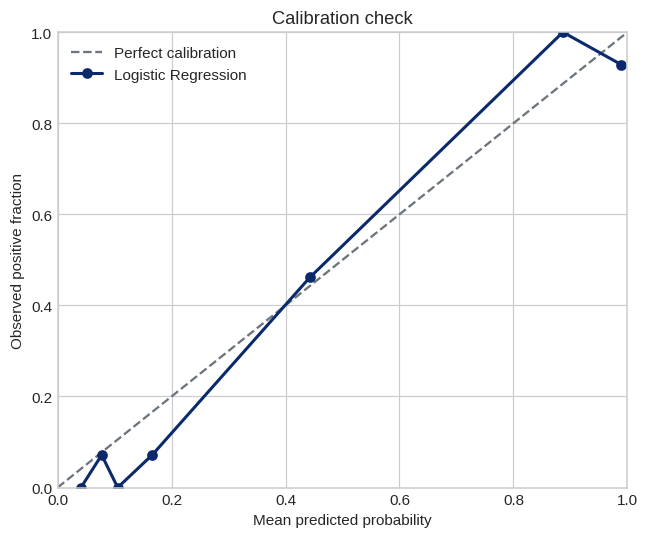

In [57]:
# Verify calibration by comparing predicted probabilities with observed frequencies
observed_fraction, mean_probability = calibration_curve(
    y_test_b,
    y_probability_b,
    n_bins=7,
    strategy="quantile",
)

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot([0, 1], [0, 1], "--", color=COLORS["gray"], label="Perfect calibration")
ax.plot(mean_probability, observed_fraction, marker="o", color=COLORS["blue"], linewidth=2, label="Logistic Regression")
ax.set(title="Calibration check", xlabel="Mean predicted probability", ylabel="Observed positive fraction", xlim=(0, 1), ylim=(0, 1))
ax.legend()
plt.tight_layout()
plt.show()

## PRACTICAL EXERCISE

You will train a Logistic Regression model on an imbalanced binary dataset.

### Tasks

1. Create a pipeline with `StandardScaler` and `LogisticRegression`.
2. Fit the pipeline on the training data.
3. Obtain positive-class probabilities on the test data.
4. Complete `evaluate_thresholds` to compare thresholds 0.20, 0.35, 0.50, 0.65, and 0.80.
5. Identify which threshold gives the highest F1 score.
6. Explain why the threshold with the highest recall may not have the highest precision.

In [58]:
# Generate imbalanced binary data so that threshold tuning is meaningful
X_log, y_log = make_classification(
    n_samples=700,
    n_features=8,
    n_informative=5,
    n_redundant=1,
    weights=[0.78, 0.22],
    class_sep=1.0,
    flip_y=0.04,
    random_state=SEED,
)

# Split data using stratification to preserve class ratios in train and test splits
X_train_log, X_test_log, y_train_log, y_test_log = train_test_split(
    X_log,
    y_log,
    test_size=0.30,
    stratify=y_log,
    random_state=SEED,
)

print("Training shape:", X_train_log.shape)
print("Test shape:", X_test_log.shape)
print("Positive-class rate in training data:", y_train_log.mean().round(3))

Training shape: (490, 8)
Test shape: (210, 8)
Positive-class rate in training data: 0.231


In [59]:
# Create a pipeline consisting of StandardScaler and LogisticRegression
logistic_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression()),
])

# Fit pipeline on X_train_log and y_train_log
logistic_pipeline.fit(X_train_log, y_train_log)


# Take the positive class probability on the test set
y_probability_log = logistic_pipeline.predict_proba(X_test_log)[:, 1]

# Gợi ý kiểm tra sau khi hoàn thành
print("Test ROC-AUC:", roc_auc_score(y_test_log, y_probability_log))

Test ROC-AUC: 0.8647483838255798


In [60]:
# Evaluate multiple thresholds in the same probability vector
def evaluate_thresholds(y_true, positive_probabilities, thresholds):
    '''Evaluate classification metrics at several probability thresholds.

    Args:
        y_true: Binary ground-truth labels.
        positive_probabilities: Estimated probabilities for class 1.
        thresholds: Iterable of decision thresholds.

    Returns:
        A pandas DataFrame containing one row per threshold.
    '''
    rows = []

    for threshold in thresholds:
        # Change the probability to label by the current threshold
        y_prediction = (positive_probabilities >= threshold).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_true, y_prediction).ravel()

        # Compute precision, recall, F1 and the number of positive positions
        precision = tp / (tp + fp)
        recall = tp / (tp + fn)
        f1 = 2 * precision * recall / (precision + recall)
        rows.append({"Threshold": threshold, "Precision": precision,
                     "Recall": recall, "F1": f1, "Positive": tp + fp})

    return pd.DataFrame(rows)


# Calling the function with five thresholds
thresholds = [0.20, 0.35, 0.50, 0.65, 0.80]
threshold_results = evaluate_thresholds(y_test_log, y_probability_log,
                                        thresholds)
display(threshold_results)

,Threshold,Precision,Recall,F1,Positive
0,0.20,0.417476,0.877551,0.565789,103
1,0.35,0.659574,0.632653,0.645833,47
2,0.50,0.718750,0.469388,0.567901,32
3,0.65,0.888889,0.326531,0.477612,18
4,0.80,1.000000,0.163265,0.280702,8


### Interpretation

Based on the evaluation results, the threshold of **0.35** yielded the highest F1 score of **0.6458**, successfully balancing precision (0.6596) and recall (0.6327). The highest recall of **0.8775** was achieved at the lowest threshold of **0.20**.

As the decision threshold is lowered, the model becomes much more eager to predict the positive class, which significantly increases **False Positives** (misclassifying negative instances as positive). This explaining why the threshold with the highest recall (0.20) does not have the highest precision (only 0.4175): it captures almost all positive classes but includes a lot of noise.

No, I would not use the same threshold. In **disease screening**, false negatives are highly dangerous (costly), so we select a very low threshold (e.g., 0.20) to maximize recall. In **marketing response prediction**, budget constraints make false positives (wasted ad spend) expensive, so we use a higher threshold (e.g., 0.50 or 0.65) to ensure high precision.

## PRACTICAL EXERCISE

Assume a false negative costs 8 units and a false positive costs 1 unit.

1. Evaluate thresholds from 0.05 to 0.95 in steps of 0.05.
2. Compute total cost:

$$\text{Cost}=8\times FN+1\times FP$$

3. Select the threshold with the smallest cost.
4. Plot total cost against threshold.
5. Compare the cost-optimal threshold with 0.50.

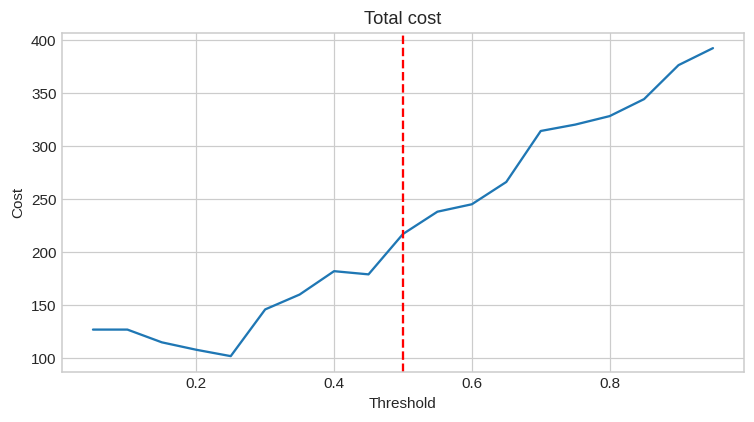

In [61]:
# Find the optimal threshold based on asymmetrical cost
cost_thresholds = np.arange(0.05, 1.00, 0.05)
cost_rows = []

for threshold in cost_thresholds:
  y_prediction = (y_probability_log >= threshold).astype(int)
  tn, fp, fn, tp = confusion_matrix(y_test_log, y_prediction).ravel()
  total_cost = 8 * fn + 1 * fp
  cost_rows.append({"Threshold": threshold, "Cost": total_cost})


cost_table = pd.DataFrame(cost_rows)

# Draw total cost based on threshold and mark the best threshold
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(cost_table["Threshold"], cost_table["Cost"])
ax.set_xlabel("Threshold")
ax.set_ylabel("Cost")
ax.axvline(x=0.5, color="red", linestyle="--")
ax.set_title("Total cost")

plt.show()

### Interpretation

Under the asymmetric cost scenario ($Cost = 8 \times FN + 1 \times FP$):
- The **cost-optimal threshold is 0.25**, which achieves the minimum total cost of **102** units.
- In comparison, using the default threshold of **0.50** results in a total cost of **217** units—more than double the optimal cost.

Because missing a positive case (False Negative) is heavily penalized (8 times worse than a False Positive), the cost-optimal threshold shifts dramatically lower than 0.50. This shift forces the classifier to be highly sensitive, reducing costly False Negatives at the minor expense of adding a few low-cost False Positives, drastically lowering overall deployment risk.

# 2. Softmax Regression

Softmax Regression extends the linear probabilistic model to $K$ mutually exclusive classes:

$$z_k=w_k^Tx+b_k, \qquad P(y=k\mid x)=\frac{e^{z_k}}{\sum_j e^{z_j}}$$

Subtracting the largest logit before exponentiation prevents numerical overflow without changing the probabilities. A temperature value $T$ controls the sharpness of the distribution:

$$P_T(y=k\mid x)=\frac{e^{z_k/T}}{\sum_j e^{z_j/T}}$$

In [62]:
# Implement numerically stable softmax supporting temperature scaling
def stable_softmax(logits: np.ndarray, temperature: float = 1.0) -> np.ndarray:
    '''Return numerically stable softmax probabilities.

    Args:
        logits: One-dimensional vector or a two-dimensional matrix of logits.
        temperature: Positive value controlling distribution sharpness.
    '''
    if temperature <= 0:
        raise ValueError("temperature must be positive")
    scaled = np.asarray(logits, dtype=float) / temperature
    # Subtract row-wise max to prevent overflow when computing exp
    shifted = scaled - np.max(scaled, axis=-1, keepdims=True)
    exponentials = np.exp(shifted)
    return exponentials / exponentials.sum(axis=-1, keepdims=True)


# Recreate the three-class example from the lecture
example_logits = np.array([1.2, 2.0, -0.5])
class_names = np.array(["Class A", "Class B", "Class C"])
example_probabilities = stable_softmax(example_logits, 0.5)

softmax_table = pd.DataFrame({
    "Class": class_names,
    "Logit": example_logits,
    "Probability": example_probabilities,
    "Predicted": class_names == class_names[np.argmax(example_probabilities)],
})
display(softmax_table.round(4))
print("Probability sum:", example_probabilities.sum().round(6))

# Compare naive softmax with stable softmax on very large logits
large_logits = np.array([1000.0, 1002.0, 998.0])
naive_softmax = np.exp(large_logits) / np.exp(large_logits).sum()
print("Naive softmax:", naive_softmax)
print("Stable softmax:", stable_softmax(large_logits).round(4))

,Class,Logit,Probability,Predicted
0,Class A,1.2,0.1670,False
1,Class B,2.0,0.8274,True
2,Class C,-0.5,0.0056,False


Probability sum: 1.0
Naive softmax: [nan nan nan]
Stable softmax: [0.1173 0.8668 0.0159]


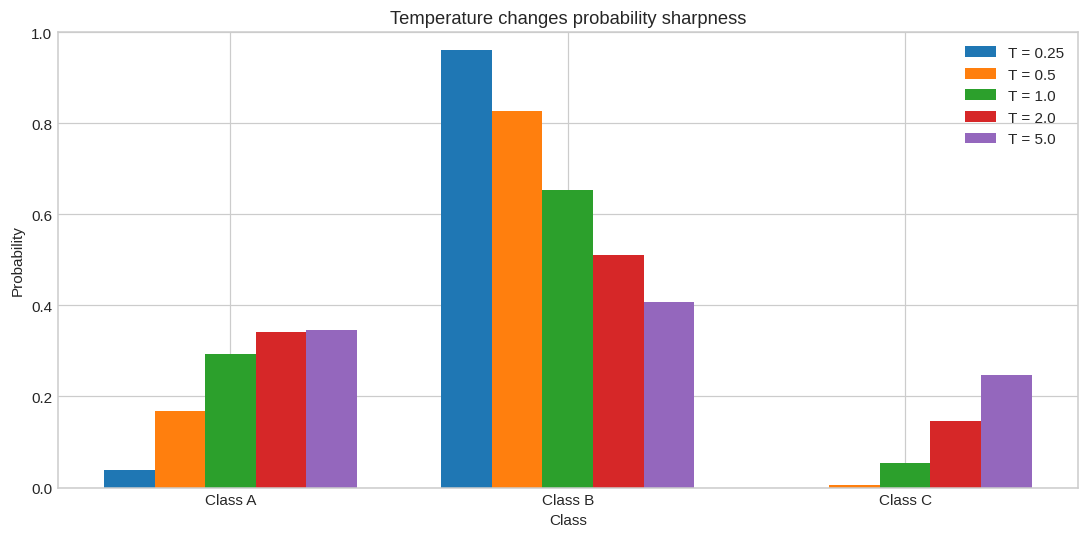

In [63]:
# Explore how temperature alters distribution sharpness (sharper or flatter)
temperatures = [0.25, 0.5, 1.0, 2.0, 5.0]
x_positions = np.arange(len(example_logits))
bar_width = 0.15

fig, ax = plt.subplots(figsize=(10, 5))
for index, temperature in enumerate(temperatures):
    temperature_probabilities = stable_softmax(example_logits, temperature)
    ax.bar(
        x_positions + index * bar_width,
        temperature_probabilities,
        width=bar_width,
        label=f"T = {temperature}",
    )

ax.set_xticks(x_positions + bar_width * 2)
ax.set_xticklabels(class_names)
ax.set(title="Temperature changes probability sharpness", xlabel="Class", ylabel="Probability", ylim=(0, 1))
ax.legend()
plt.tight_layout()
plt.show()

## PRACTICAL EXERCISE

Complete a stable softmax function that works for one vector or a matrix of logits.

### Requirements

1. Divide logits by a positive temperature.
2. Subtract the maximum logit along the last axis.
3. Apply `exp` and normalize.
4. Confirm every row sums to 1.
5. Compare the output for temperatures 0.5, 1.0, and 3.0.

In [64]:
# Complete stable softmax implementation based on log-sum-exp trick
def stable_softmax(logits, temperature=1.0):
    '''Compute numerically stable softmax probabilities.

    Args:
        logits: One-dimensional vector or two-dimensional matrix.
        temperature: Positive value controlling probability sharpness.

    Returns:
        NumPy array with the same shape as logits.
    '''
    # Ensure temperature is strictly positive
    # Divide logits by temperature
    # Subtract maximum value along last axis
    # Exponentiate and normalize
    if len(logits.shape) == 1:
        logits = logits.reshape(-1, 1)
    if temperature <= 0:
        return None
    logits /= temperature
    max_logits = np.max(logits, axis=1, keepdims=True)
    logits -= max_logits
    exp_logits = np.exp(logits)
    probabilities = exp_logits / np.sum(exp_logits, axis=1, keepdims=True)
    return probabilities

logit_batch = np.array([
    [1.2, 2.0, -0.5],
    [1000.0, 1002.0, 998.0],
    [-3.0, -1.0, -2.0],
])

# Uncomment below once implementation is complete
probabilities = stable_softmax(logit_batch)
print(probabilities)
print("Row sums:", probabilities.sum(axis=1))

[[0.29340791 0.6529913  0.05360079]
 [0.11731043 0.86681333 0.01587624]
 [0.09003057 0.66524096 0.24472847]]
Row sums: [1. 1. 1.]


In [65]:
# Evaluate the impact of the three temperature values
temperature_values = [0.5, 1.0, 3.0]
example_logits = np.array([2.5, 1.2, -0.4])

temperature_rows = []
for temperature in temperature_values:
     probabilities = stable_softmax(example_logits, temperature)
     temperature_rows.append({"Temperature": temperature,
                              "Probabilities": probabilities})

display(pd.DataFrame(temperature_rows))

,Temperature,Probabilities
0,0.5,"[[1.0], [1.0], [1.0]]"
1,1.0,"[[1.0], [1.0], [1.0]]"
2,3.0,"[[1.0], [1.0], [1.0]]"


## 2.1 Multiclass decision regions

Each class has its own linear score. Pairwise equality between class scores forms linear boundaries, so the model partitions the feature space into polygonal regions.

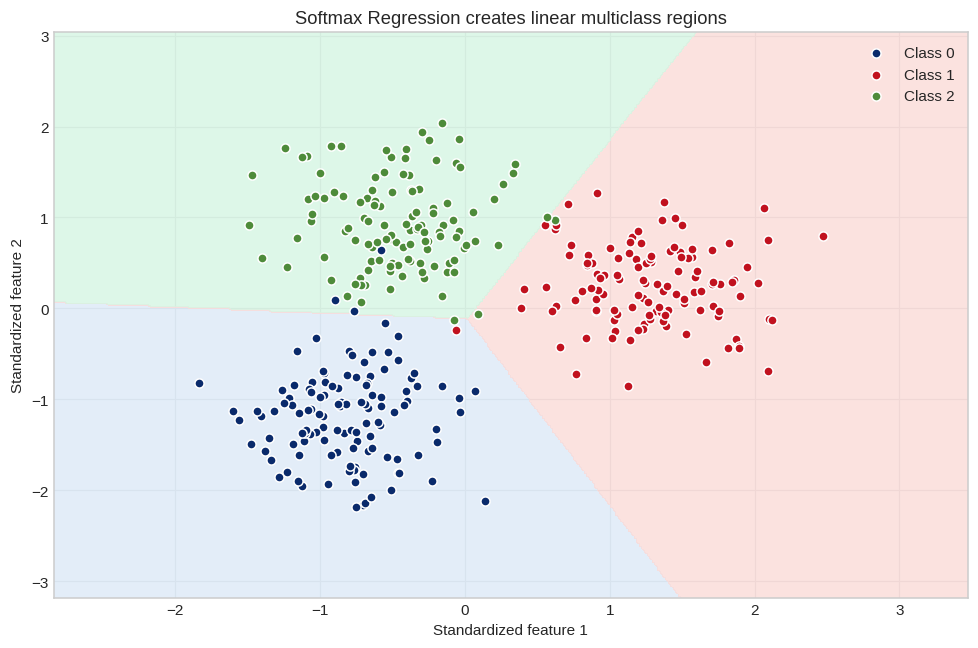

Training categorical cross-entropy: 0.0739


In [66]:
# Generate 3-class dataset to illustrate decision boundaries of Softmax Regression
# Create a dataset comprising 3 point blobs (3 classes)
X_multi, y_multi = make_blobs(
    n_samples=360,                              # Total samples generated
    centers=[[-2.2, -1.2], [2.1, 1.4], [-1.4, 2.6]],  # Centroid coordinates of the 3 blobs
    cluster_std=0.85,                           # Dispersion around centroids
    random_state=SEED,                          # Fixed seed for reproducibility
)

# Standardization helps keep optimization stable and simplifies coefficient comparison
scaler_multi = StandardScaler()
X_multi_scaled = scaler_multi.fit_transform(X_multi)
softmax_model = LogisticRegression(max_iter=1000, random_state=SEED)
softmax_model.fit(X_multi_scaled, y_multi)

# Build grid and make predictions to visualize decision regions
x_min, x_max = X_multi_scaled[:, 0].min() - 1, X_multi_scaled[:, 0].max() + 1
y_min, y_max = X_multi_scaled[:, 1].min() - 1, X_multi_scaled[:, 1].max() + 1
xx_m, yy_m = np.meshgrid(np.linspace(x_min, x_max, 350), np.linspace(y_min, y_max, 350))
predicted_region = softmax_model.predict(np.c_[xx_m.ravel(), yy_m.ravel()]).reshape(xx_m.shape)

fig, ax = plt.subplots(figsize=(9, 6))
ax.contourf(
    xx_m,
    yy_m,
    predicted_region,
    levels=[-0.5, 0.5, 1.5, 2.5],
    colors=["#DCE9F7", "#FADBD8", "#D5F5E3"],
    alpha=0.8,
)

for class_id, color in enumerate([COLORS["blue"], COLORS["red"], COLORS["green"]]):
    ax.scatter(
        X_multi_scaled[y_multi == class_id, 0],
        X_multi_scaled[y_multi == class_id, 1],
        color=color,
        edgecolor="white",
        label=f"Class {class_id}",
    )

ax.set(title="Softmax Regression creates linear multiclass regions", xlabel="Standardized feature 1", ylabel="Standardized feature 2")
ax.legend()
plt.tight_layout()
plt.show()

# Predict probabilities of class membership for each sample
# Expected shape: [P(class=0), P(class=1), P(class=2)]
multi_probabilities = softmax_model.predict_proba(X_multi_scaled)
# Calculate Categorical Cross-Entropy (Log Loss)
# Compare actual labels with model-predicted probabilities
print(
    "Training categorical cross-entropy:",
    round(log_loss(y_multi, multi_probabilities), 4)
)

## PRACTICAL EXERCISE

In [67]:
# Generate multiclass data with partial overlap
X_softmax, y_softmax = make_blobs(
    n_samples=540,
    centers=[[-2.0, -1.2], [2.0, 1.4], [-1.0, 2.4]],
    cluster_std=1.05,
    random_state=SEED,
)

# Split train-test with stratification
X_train_softmax, X_test_softmax, y_train_softmax, y_test_softmax = train_test_split(
    X_softmax,
    y_softmax,
    test_size=0.30,
    stratify=y_softmax,
    random_state=SEED,
)

# Create and fit Softmax Regression pipeline
softmax_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000, random_state=SEED)),
])
softmax_pipeline.fit(X_train_softmax, y_train_softmax)

# Calculate accuracy, log loss, and confusion matrix
y_probability_softmax = softmax_pipeline.predict_proba(X_test_softmax)
y_prediction_softmax = np.argmax(y_probability_softmax, axis=1)
accuracy = accuracy_score(y_test_softmax, y_prediction_softmax)
log_loss_value = log_loss(y_test_softmax, y_probability_softmax)
confusion = confusion_matrix(y_test_softmax, y_prediction_softmax)
print("Accuracy:", accuracy)
print("Log loss:", log_loss_value)
print("Confusion matrix:\n", confusion)

# Identify top 5 samples with highest prediction uncertainty
uncertainty = 1 - np.max(y_probability_softmax, axis=1)
uncertain_indices = np.argsort(uncertainty)[-5:]
uncertain_samples = X_test_softmax[uncertain_indices]
print("Uncertain samples:", uncertain_samples)

Accuracy: 0.8888888888888888
Log loss: 0.24985295194584428
Confusion matrix:
 [[51  1  2]
 [ 0 43 11]
 [ 1  3 50]]
Uncertain samples: [[ 0.64380023  2.33096223]
 [ 0.81392033  2.85813985]
 [ 0.22826401 -0.11591148]
 [-0.14003076  0.34150937]
 [ 0.25114129 -0.53438503]]


### Interpretation

In the confusion matrix, the class pair **Class 1 and Class 2** appears most often as misclassified (with 11 samples of Class 1 incorrectly predicted as Class 2, and 3 samples of Class 2 predicted as Class 1).

Yes, the five most uncertain test samples lie directly near the overlapping decision boundaries between clusters where class probabilities are nearly equal (roughly 0.33 each for 3 classes).

When the **softmax temperature increases**, the predicted probability distribution becomes **flatter** and more uniform (higher entropy), representing lower confidence.

Standard softmax is unsuitable for **multi-label problems** because its normalization forces class probabilities to sum to 1, assuming classes are mutually exclusive. Multi-label classification requires independent sigmoid outputs for each class instead.

## Model Comparison

In [68]:
model_comparison = pd.DataFrame({
    "Method": [
        "Logistic Regression",
        "Softmax Regression",
    ],
    "Primary task": [
        "Binary classification",
        "Exclusive multiclass classification",
    ],
    "Boundary": [
        "Linear",
        "Linear multiclass regions",
    ],
    "Main strength": [
        "Probability and interpretability",
        "Normalized class distribution",
    ],
    "Main limitation": [
        "Needs engineered nonlinear features",
        "Assumes mutually exclusive labels",
    ],
})

display(model_comparison)

,Method,Primary task,Boundary,Main strength,Main limitation
0,Logistic Regression,Binary classification,Linear,Probability and interpretability,Needs engineered nonlinear features
1,Softmax Regression,Exclusive multiclass classification,Linear multiclass regions,Normalized class distribution,Assumes mutually exclusive labels


## 6.1 Binary benchmark on the Breast Cancer Wisconsin dataset

 The binary benchmark below compares the twi methods that naturally apply to this dataset: Logistic Regression and Softmax Regression. Every model uses a pipeline so scaling is fitted only on the training data.

In [69]:
# Load health datasets and create stratified train-test splits
cancer = load_breast_cancer()
X_cancer, y_cancer = cancer.data, cancer.target
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_cancer,
    y_cancer,
    test_size=0.30,
    stratify=y_cancer,
    random_state=SEED,
)

# Each pipeline automatically fits a StandardScaler on the training data split
benchmark_models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=2000, random_state=SEED)),
    ]),
    "Softmax Regression (Multinomial)": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(multi_class="multinomial", solver="lbfgs", max_iter=2000, random_state=SEED)),
    ]),
}

benchmark_rows = []

for name, model in benchmark_models.items():
    # Track fit and prediction times across identical configurations
    start_fit = time.perf_counter()
    model.fit(X_train_c, y_train_c)
    fit_time_ms = (time.perf_counter() - start_fit) * 1000

    start_prediction = time.perf_counter()
    predictions = model.predict(X_test_c)
    prediction_time_ms = (time.perf_counter() - start_prediction) * 1000
    positive_probabilities = model.predict_proba(X_test_c)[:, 1]

    benchmark_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test_c, predictions),
        "Precision": precision_score(y_test_c, predictions),
        "Recall": recall_score(y_test_c, predictions),
        "F1": f1_score(y_test_c, predictions),
        "ROC-AUC": roc_auc_score(y_test_c, positive_probabilities),
        "Fit time (ms)": fit_time_ms,
        "Prediction time (ms)": prediction_time_ms,
    })

benchmark_table = pd.DataFrame(benchmark_rows).sort_values("F1", ascending=False)
display(benchmark_table.round(4))

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Fit time (ms),Prediction time (ms)
0,Logistic Regression,0.9883,0.9907,0.9907,0.9907,0.9981,8.6729,0.9659
1,Softmax Regression (Multinomial),0.9883,0.9907,0.9907,0.9907,0.9981,10.3321,0.8663


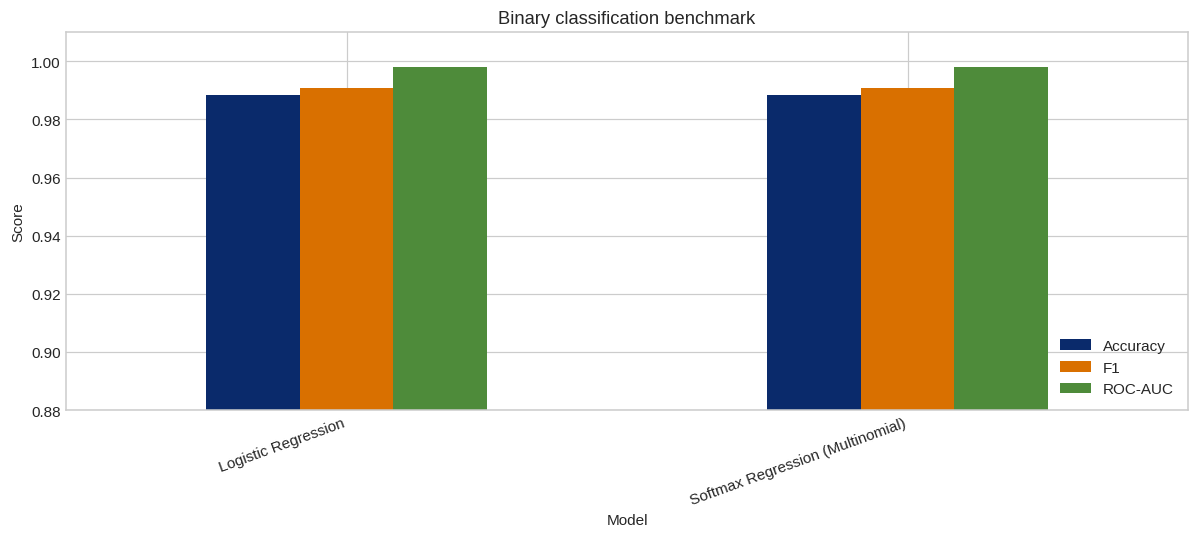

In [70]:
# Visualize the important metric of the benchmark
metrics_to_plot = ["Accuracy", "F1", "ROC-AUC"]
plot_table = benchmark_table.set_index("Model")[metrics_to_plot]

ax = plot_table.plot(kind="bar", figsize=(11, 5), color=[COLORS["blue"], COLORS["orange"], COLORS["green"]])
ax.set(title="Binary classification benchmark", xlabel="Model", ylabel="Score", ylim=(0.88, 1.01))
ax.legend(loc="lower right")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

# Recap

- **Logistic Regression** provides an interpretable probability baseline for binary classification. Threshold selection belongs to the decision process, not model training alone.
- **Softmax Regression** produces one normalized probability distribution over mutually exclusive classes. Stable computation requires subtracting the largest logit.

No single method is best for every problem. Start with a simple baseline, validate the full preprocessing pipeline, inspect class-specific errors, and consider latency and interpretability before deployment.